### News

**Read our [Gemma 3 blog](https://unsloth.ai/blog/gemma3) for what's new in Unsloth and our [Reasoning blog](https://unsloth.ai/blog/r1-reasoning) on how to train reasoning models.**

Visit our docs for all our [model uploads](https://docs.unsloth.ai/get-started/all-our-models) and [notebooks](https://docs.unsloth.ai/get-started/unsloth-notebooks).


### Installation

In [2]:
%%capture
import os
if "COLAB_" not in "".join(os.environ.keys()):
    !pip install unsloth vllm
else:
    # [NOTE] Do the below ONLY in Colab! Use [[pip install unsloth vllm]]
    !pip install --no-deps unsloth vllm
# Install latest Hugging Face for Gemma-3!
!pip install --no-deps git+https://github.com/huggingface/transformers@v4.49.0-Gemma-3
!pip install bitsandbytes
!pip install unsloth_zoo
!pip install msgspec
!pip install blake3
!pip install gguf
!pip install networkx==2.8.8 --force-reinstall

In [5]:
#@title Colab Extra Install { display-mode: "form" }
%%capture
import os
if "COLAB_" not in "".join(os.environ.keys()):
    !pip install unsloth vllm
else:
    !pip install --no-deps unsloth vllm
    # [NOTE] Do the below ONLY in Colab! Use [[pip install unsloth vllm]]
    # Skip restarting message in Colab
    import sys, re, requests; modules = list(sys.modules.keys())
    for x in modules: sys.modules.pop(x) if "PIL" in x or "google" in x else None
    !pip install --no-deps bitsandbytes accelerate xformers==0.0.29.post3 peft trl triton cut_cross_entropy unsloth_zoo
    !pip install sentencepiece protobuf datasets huggingface_hub hf_transfer

    # vLLM requirements - vLLM breaks Colab due to reinstalling numpy
    f = requests.get("https://raw.githubusercontent.com/vllm-project/vllm/refs/heads/main/requirements/common.txt").content
    with open("vllm_requirements.txt", "wb") as file:
        file.write(re.sub(rb"(transformers|numpy|xformers)[^\n]{1,}\n", b"", f))
    !pip install -r vllm_requirements.txt

In [ ]:
!pip install --force-reinstall pillow

# Restart the runtime programmatically to apply the changes
import os
os.kill(os.getpid(), 9)

  Using cached pillow-13.0.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
Using cached pillow-13.0.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (7.1 MB)
  Attempting uninstall: pillow
    Found existing installation: pillow 13.0.0
    Uninstalling pillow-13.0.0:
      Successfully uninstalled pillow-13.0.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
vllm 0.34.0 requires fastsafetensors>=0.3.3, which is not installed.
vllm 0.34.0 requires flashinfer-python==0.7.3, which is not installed.
vllm 0.34.0 requires humming-kernels[cu13]==0.1.19, which is not installed.
vllm 0.34.0 requires instanttensor>=0.2.2, which is not installed.
vllm 0.34.0 requires nvidia-cudnn-frontend>=1.31.0, which is not installed.
vllm 0.34.0 requires nvidia-cutlass-dsl[cu13]==4.8.0, which is not installed.
vllm 0.34.0 requires nvtx==0.2

### Unsloth

`FastModel` supports loading nearly any model now! This includes Vision and Text models!

In [3]:
from unsloth import FastModel
import torch

fourbit_models = [
    # 4bit dynamic quants for superior accuracy and low memory use
    "unsloth/gemma-3-1b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-4b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-12b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-27b-it-unsloth-bnb-4bit",

    # Other popular models!
    "unsloth/Llama-3.1-8B",
    "unsloth/Llama-3.2-3B",
    "unsloth/Llama-3.3-70B",
    "unsloth/mistral-7b-instruct-v0.3",
    "unsloth/Phi-4",
] # More models at https://huggingface.co/unsloth

model, tokenizer = FastModel.from_pretrained(
    model_name = "unsloth/gemma-3-4b-it",
    max_seq_length = 2048, # Choose any for long context!
    load_in_4bit = True,  # 4 bit quantization to reduce memory
    load_in_8bit = False, # [NEW!] A bit more accurate, uses 2x memory
    full_finetuning = False, # [NEW!] We have full finetuning now!
    # token = "hf_...", # use one if using gated models
)

Please reinstall via `uv pip install unsloth vllm torchvision torchaudio --torch-backend=auto`.
W1118 11:25:53.205000 6430 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1118 11:25:53.307000 6430 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth 2026.11.6: no GPU found, training on CPU (x86_64, 1 threads, bfloat16 = False). CPU training is much slower than GPU training; supported: text LoRA / full finetuning with SFTTrainer. Set UNSLOTH_DISABLE_CPU_FALLBACK=1 to raise instead.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/90.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

... (5 outputs left out)

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/670 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

Unsloth (CPU): Gemma3ForConditionalGeneration on 1 CPU threads. dtype = torch.float32, 4-bit = True, chunked CE = False.


We now add LoRA adapters so we only need to update a small amount of parameters!

In [4]:
model = FastModel.get_peft_model(
    model,
    finetune_vision_layers     = False, # Turn off for just text!
    finetune_language_layers   = True,  # Should leave on!
    finetune_attention_modules = True,  # Attention good for GRPO
    finetune_mlp_modules       = True,  # SHould leave on always!

    r = 16,           # Larger = higher accuracy, but might overfit
    lora_alpha = 16,  # Recommended alpha == r at least
    lora_dropout = 0,
    bias = "none",
    random_state = 3407,
)

<a name="Data"></a>
### Data Prep
We now use the `Gemma-3` format for conversation style finetunes. We use [Maxime Labonne's FineTome-100k](https://huggingface.co/datasets/mlabonne/FineTome-100k) dataset in ShareGPT style. Gemma-3 renders multi turn conversations like below:

```
<bos><start_of_turn>user
Hello!<end_of_turn>
<start_of_turn>model
Hey there!<end_of_turn>
```

We use our `get_chat_template` function to get the correct chat template. We support `zephyr, chatml, mistral, llama, alpaca, vicuna, vicuna_old, phi3, llama3, phi4, qwen2.5, gemma3` and more.

In [5]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)

In [6]:
from datasets import load_dataset

# Load CSV dataset
dataset = load_dataset(
    "csv",
    data_files="/content/dataasilida_cleaned.csv"
)

# Split dataset: 80% training, 20% validation
dataset = dataset["train"].train_test_split(
    test_size=0.2,
    seed=3407
)

# Check dataset sizes
print(dataset)


Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input', 'output'],
        num_rows: 416
    })
    test: Dataset({
        features: ['input', 'output'],
        num_rows: 105
    })
})


In [7]:
dataset['train']['input'][0]

'តើសេវាផ្ទេរប្រាក់ទូទាត់ជាកញ្ចប់ មានការកំណត់ចំនួនប្រតិបត្តិការប្រចំាថ្ងៃដែរឬទេ'

In [8]:
def formatting_prompts_func(examples):
    instructions = examples["input"]
    outputs      = examples["output"]
    texts = []
    for instruction, output in zip(instructions, outputs):
      messages = [
        {
            "role": "user", 'content': instruction.strip(" ")
          },
          {
            "role": "assistant", 'content': output
          }
      ]
      #tokenizer.apply_chat_template(messages, add_generation_prompt=False , tokenize= False)
      text = tokenizer.apply_chat_template(messages, add_generation_prompt=False , tokenize= False)
      texts.append(text)
    return {"text":texts}



In [9]:
dataset = dataset.map(formatting_prompts_func, batched = True,)

Map:   0%|          | 0/416 [00:00<?, ? examples/s]

Map:   0%|          | 0/105 [00:00<?, ? examples/s]

In [10]:
dataset['train']['text'][0]

'<bos><start_of_turn>user\nតើសេវាផ្ទេរប្រាក់ទូទាត់ជាកញ្ចប់ មានការកំណត់ចំនួនប្រតិបត្តិការប្រចំាថ្ងៃដែរឬទេ<end_of_turn>\n<start_of_turn>model\nចំនួនទឹកប្រាក់ និងចំនួនប្រតិបត្តិការអតិបរមា (File Uploaded) ក្នុងមួយថ្ងៃ គឺមិនកំណត់។<end_of_turn>\n'

Let's see how row 100 looks like!

In [11]:
dataset['train']['input'][0]

'តើសេវាផ្ទេរប្រាក់ទូទាត់ជាកញ្ចប់ មានការកំណត់ចំនួនប្រតិបត្តិការប្រចំាថ្ងៃដែរឬទេ'

In [12]:
dataset['train']['input'][0]

'តើសេវាផ្ទេរប្រាក់ទូទាត់ជាកញ្ចប់ មានការកំណត់ចំនួនប្រតិបត្តិការប្រចំាថ្ងៃដែរឬទេ'

Let's see how the chat template did! Notice `Gemma-3` default adds a `<bos>`!

In [13]:
dataset['train']['output'][00]

'ចំនួនទឹកប្រាក់ និងចំនួនប្រតិបត្តិការអតិបរមា (File Uploaded) ក្នុងមួយថ្ងៃ គឺមិនកំណត់។'

<a name="Train"></a>
### Train the model
Now let's use Huggingface TRL's `SFTTrainer`! More docs here: [TRL SFT docs](https://huggingface.co/docs/trl/sft_trainer). We do 60 steps to speed things up, but you can set `num_train_epochs=1` for a full run, and turn off `max_steps=None`.

In [14]:
import wandb

# This will prompt you for your WandB API key.
# You can find your key at https://wandb.ai/authorize
wandb.login()

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: sotheara_heang (sotheara_heang-institute-of-technology-of-cambodia) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [15]:
from trl import SFTTrainer
from transformers import TrainingArguments
from unsloth import is_bfloat16_supported

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = dataset['train'],
    eval_dataset = dataset["test"],
    dataset_text_field = "text",
    #max_seq_length = max_seq_length,
    dataset_num_proc = 2,
    packing = False, # Can make training 5x faster for short sequences.
    args = TrainingArguments(
        per_device_train_batch_size = 2,
        gradient_accumulation_steps = 4,
        warmup_steps = 5,
        max_steps = 100,
        learning_rate = 2e-4,
        fp16 = not is_bfloat16_supported(),
        bf16 = is_bfloat16_supported(),
        logging_steps = 1,
        optim = "adamw_8bit",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
        report_to = "wandb",
        eval_strategy = "steps",
        eval_steps = 10,
    ),
)

Unsloth (CPU): optim = 'adamw_8bit' needs a GPU, using 'adamw_torch_fused'.


Adding EOS to train dataset (num_proc=2):   0%|          | 0/416 [00:00<?, ? examples/s]

Tokenizing train dataset (num_proc=2):   0%|          | 0/416 [00:00<?, ? examples/s]

Building labels for train dataset (num_proc=2):   0%|          | 0/416 [00:00<?, ? examples/s]

Truncating train dataset (num_proc=2):   0%|          | 0/416 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset (num_proc=2):   0%|          | 0/416 [00:00<?, ? examples/s]

Adding EOS to eval dataset (num_proc=2):   0%|          | 0/105 [00:00<?, ? examples/s]

Tokenizing eval dataset (num_proc=2):   0%|          | 0/105 [00:00<?, ? examples/s]

Building labels for eval dataset (num_proc=2):   0%|          | 0/105 [00:00<?, ? examples/s]

Truncating eval dataset (num_proc=2):   0%|          | 0/105 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset (num_proc=2):   0%|          | 0/105 [00:00<?, ? examples/s]

We also use Unsloth's `train_on_completions` method to only train on the assistant outputs and ignore the loss on the user's inputs. This helps increase accuracy of finetunes!

In [16]:
from unsloth.chat_templates import train_on_responses_only
trainer = train_on_responses_only(
    trainer,
    instruction_part = "<start_of_turn>user\n",
    response_part = "<start_of_turn>model\n",
)

Unsloth: not enough free memory for dataset tokenization workers (~1GB each); tokenizing in-process.


Map:   0%|          | 0/416 [00:00<?, ? examples/s]

Map:   0%|          | 0/105 [00:00<?, ? examples/s]

Unsloth: Dropping columns the model is not fed: ['input', 'output', 'text']
Unsloth: Dropping columns the model is not fed: ['input', 'output', 'text']


Let's verify masking the instruction part is done! Let's print the 100th row again:

In [17]:
tokenizer.decode(trainer.train_dataset[100]["input_ids"])

'<bos><bos><start_of_turn>user\nតើឥណទាននេះមានប្រភេទរូបបិយប័ណ្ណ អ្វីខ្លះ<end_of_turn>\n<start_of_turn>model\nសម្រាប់ឥណទាននិស្សិត ត្រូវបានផ្តល់ជូនជាប្រាក់ដុល្លារអាមេរិក តែប៉ុណ្ណោះ ។<end_of_turn>\n<end_of_turn>'

Now let's print the masked out example - you should see only the answer is present:

In [18]:
tokenizer.decode([tokenizer.pad_token_id if x == -100 else x for x in trainer.train_dataset[100]["labels"]]).replace(tokenizer.pad_token, " ")

'                               សម្រាប់ឥណទាននិស្សិត ត្រូវបានផ្តល់ជូនជាប្រាក់ដុល្លារអាមេរិក តែប៉ុណ្ណោះ ។<end_of_turn>  '

In [ ]:
# @title Show current memory stats
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

Let's train the model! To resume a training run, set `trainer.train(resume_from_checkpoint = True)`

In [ ]:
trainer_stats = trainer.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 106}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 416 | Num Epochs = 2 | Total steps = 100
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 29,802,496 of 4,329,881,968 (0.69% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
10,2.068999,1.961409
20,1.667937,1.633695
30,1.447371,1.546465
40,1.501591,1.448856
50,1.098169,1.417571
60,1.244098,1.395424
70,1.406261,1.347042
80,1.058852,1.323663
90,1.282437,1.314187
100,1.076637,1.309015


Filter:   0%|          | 0/105 [00:00<?, ? examples/s]

Unsloth: Not an error, but `num_items_in_batch` could not be counted for Gemma3ForConditionalGeneration's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-100/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-100.


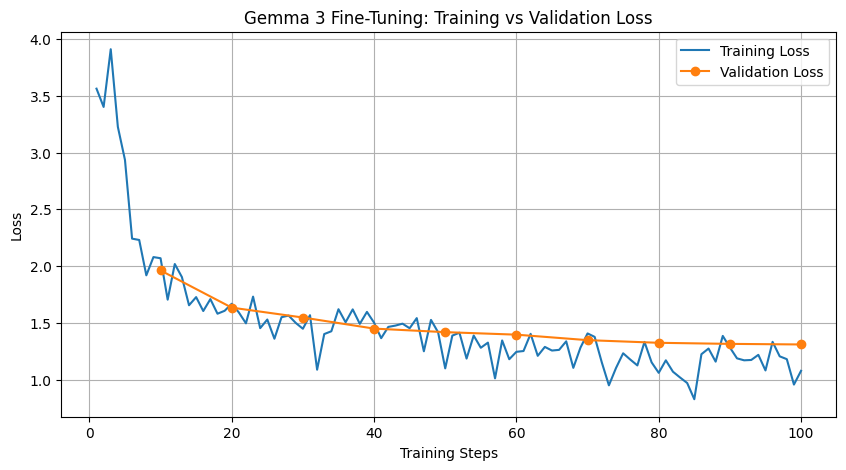

In [ ]:
import matplotlib.pyplot as plt

logs = trainer.state.log_history

train_steps = [
    x["step"] for x in logs if "loss" in x
]
train_losses = [
    x["loss"] for x in logs if "loss" in x
]

eval_steps = [
    x["step"] for x in logs if "eval_loss" in x
]
eval_losses = [
    x["eval_loss"] for x in logs if "eval_loss" in x
]

plt.figure(figsize=(10, 5))

plt.plot(
    train_steps,
    train_losses,
    label="Training Loss"
)

plt.plot(
    eval_steps,
    eval_losses,
    label="Validation Loss",
    marker="o"
)

plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Gemma 3 Fine-Tuning: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# @title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(
    f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training."
)
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

**Interpret** Training and Validation Loss Analysis

During fine-tuning of the Gemma 3 4B model on the Khmer question-answering dataset, both training loss and validation loss showed an overall decreasing trend over 120 training steps.

Training loss fluctuated considerably but decreased overall, indicating that the model was learning from the training examples. These fluctuations are expected with small training batches.

Validation loss decreased more smoothly, from approximately 1.46 to 1.25, indicating improving generalization to held-out validation examples. However, the rate of improvement became smaller during the later training steps.

Although the gap between training and validation loss increased, there was no clear evidence of overfitting because validation loss did not show a sustained increase.

Overall, the fine-tuning process demonstrated stable validation improvement, with indications that the model was approaching a plateau. Further evaluation of generated answers is necessary to determine whether the improvements in loss correspond to better question-answering performance.

<a name="Inference"></a>
### Inference
Let's run the model via Unsloth native inference! According to the `Gemma-3` team, the recommended settings for inference are `temperature = 1.0, top_p = 0.95, top_k = 64`

In [ ]:
from unsloth.chat_templates import get_chat_template

tokenizer = get_chat_template(
    tokenizer,
    chat_template="gemma-3"
)

# Enter your own question here
#question = "តើអ្វីទៅជា​ធនាគារ អេស៊ីលីដា?"
question = "តើធនាគារ អេស៊ីលីដា មានសេវាកម្មអ្វីខ្លះ?"
#question = "តើធនាគារ អេស៊ីលីដា បង្កើតឡើងនៅឆ្នាំណា?"
#question = "What services does ACLEDA Bank provide?"

messages = [{
    "role": "user",
    "content": [{
        "type": "text",
        "text": question
    }]
}]

# Format question for Gemma 3
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=False
)

# Tokenize input
inputs = tokenizer(
    [text],
    return_tensors="pt"
).to("cuda")

# Generate answer
model.eval()

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=256,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

# Extract generated answer only
answer_tokens = outputs[0][
    inputs["input_ids"].shape[1]:
]

answer = tokenizer.decode(
    answer_tokens,
    skip_special_tokens=True
)

print("Question:", question)
print("Answer:", answer)

Question: តើធនាគារ អេស៊ីលីដា មានសេវាកម្មអ្វីខ្លះ?
Answer: ធនាគារ អេស៊ីលីដា ផ្តល់ជូនអតិថិជននូវសេវាកម្មដូចខាងក្រោម៖ \n កម្ចីប្រាក់ \n កម្ចីសម្រាប់ទិញទំនិញ \n កម្ចីសម្រាប់ទិញអគារ \n កម្ចីសម្រាប់ទិញកិច្ចសន្យា \n កម្ចីសម្រាប់ទិញទំនិញតាមអនឡាញ \n ផ្តល់ជូនសេវាកម្មផ្តល់ឥណពន្ធ \n ផ្តល់ជូនសេវាកម្មផ្តល់ឥណពន្ធតាមអនឡាញ \n ផ្តល់ជូនសេវាកម្មផ្តល់ឥណពន្ធសម្រាប់ទំនិញ \n ផ្តល់ជូនសេវាកម្មផ្តល់ឥណពន្ធសម្រាប់ទំនិញតាមអនឡាញ \n ផ្តល់ជូនសេវាកម្មផ្តល់ឥណពន្ធសម្រាប់ទំនិញតាមអនឡាញ \n ផ្តល់ជូនសេវាកម្មផ្តល់ឥណពន្ធសម្រាប់ទំនិញតាមអនឡាញ \n ផ្តល់ជូនសេវាកម្មផ្តល់ឥណពន្ធសម្រាប់ទំនិញតាមអនឡាញ \


 You can also use a `TextStreamer` for continuous inference - so you can see the generation token by token, instead of waiting the whole time!

In [ ]:
messages = [{
    "role": "user",
    "content": [{"type" : "text", "text" : "ទៅមុខ១០ម",}]
}]
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True, # Must add for generation
)

from transformers import TextStreamer
_ = model.generate(
    **tokenizer([text], return_tensors = "pt").to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
    streamer = TextStreamer(tokenizer, skip_prompt = True),
)

{'action':'move','params':{'distance':10,'is_forward':True,'unit':'meter'}}<end_of_turn>


<a name="Save"></a>
### Saving, loading finetuned models
To save the final model as LoRA adapters, either use Huggingface's `push_to_hub` for an online save or `save_pretrained` for a local save.

**[NOTE]** This ONLY saves the LoRA adapters, and not the full model. To save to 16bit or GGUF, scroll down!

In [ ]:
model.save_pretrained("gemma-3")  # Local saving
tokenizer.save_pretrained("gemma-3")
# model.push_to_hub("HF_ACCOUNT/gemma-3", token = "...") # Online saving
# tokenizer.push_to_hub("HF_ACCOUNT/gemma-3", token = "...") # Online saving

['gemma-3/processor_config.json']

Now if you want to load the LoRA adapters we just saved for inference, set `False` to `True`:

In [ ]:
if False:
    from unsloth import FastModel
    model, tokenizer = FastModel.from_pretrained(
        model_name = "lora_model", # YOUR MODEL YOU USED FOR TRAINING
        max_seq_length = 2048,
        load_in_4bit = True,
    )

messages = [{
    "role": "user",
    "content": [{"type" : "text", "text" : "បន្តទៅក្រោយ៩ម",}]
}]
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True, # Must add for generation
)

from transformers import TextStreamer
_ = model.generate(
    **tokenizer([text], return_tensors = "pt").to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
    streamer = TextStreamer(tokenizer, skip_prompt = True),
)

{'action':'move','params':{'distance':9,'is_forward':False,'unit':'meter'}}<end_of_turn>


### Saving to float16 for VLLM

We also support saving to `float16` directly for deployment! We save it in the folder `gemma-3-finetune`. Set `if False` to `if True` to let it run!

In [ ]:
if False: # Change to True to save finetune!
    model.save_pretrained_merged("gemma-3-finetune", tokenizer)

If you want to upload / push to your Hugging Face account, set `if False` to `if True` and add your Hugging Face token and upload location!

In [ ]:
if False: # Change to True to upload finetune
    model.push_to_hub_merged(
        "HF_ACCOUNT/gemma-3-finetune", tokenizer,
        token = "hf_..."
    )

In [ ]:
if False: # Change to True to save to GGUF
    model.save_pretrained_gguf(
        "gemma-3-finetune",
        quantization_type = "Q8_0", # For now only Q8_0, BF16, F16 supported
    )

Likewise, if you want to instead push to GGUF to your Hugging Face account, set `if False` to `if True` and add your Hugging Face token and upload location!

In [ ]:
if False: # Change to True to upload GGUF
    model.push_to_hub_gguf(
        "gemma-3-finetune",
        quantization_type = "Q8_0", # Only Q8_0, BF16, F16 supported
        repo_id = "HF_ACCOUNT/gemma-finetune-gguf",
        token = "hf_...",
    )